# **Part 1: Visualization & Exploratory Data Analysis (EDA)**

### **Dataset Introduction**

In this project, we will work with the Palmer Penguins dataset, which contains measurements of penguins observed on islands near Antarctica.

Please download the dataset [penguins.csv](https://drive.google.com/file/d/1dv8A8v_sdf29p1At40S7KBslJPmBA3e9/view?usp=sharing) or from canvas.

### **Dataset Description**

Each row represents a penguin, and columns include:

- species – Penguin species
- island – Island where the penguin was found
- bill_length_mm – Bill length (mm)
- bill_depth_mm – Bill depth (mm)
- flipper_length_mm – Flipper length (mm)
- body_mass_g – Body mass (grams)
- sex – Sex of the penguin

Some values are missing, which makes this dataset ideal for practicing missing data handling.



Your task is to perform a comprehensive Exploratory Data Analysis (EDA) and visualization on the Palmer Penguins dataset. This project aims to deepen your understanding of data characteristics, relationships between variables, and effective data presentation using Python's data science libraries.

**Instructions:**

1.  **Load the Dataset:** Begin by loading the `penguins.csv` dataset into a pandas DataFrame.
2.  **Initial Data Inspection:** Perform an initial inspection to understand the dataset's structure. Display the first few rows, check data types and non-null values, and generate descriptive statistics.
3.  **Handle Missing Values:** Identify and address any missing values in the dataset. Clearly explain your chosen strategy for handling missing data (e.g., imputation, dropping rows/columns) and justify your decision.
4.  **Perform EDA and Visualization:** Conduct a thorough EDA, exploring distributions, relationships, and patterns within the data. You are required to use **at least three distinct types of visualizations** (e.g., histograms, scatter plots, box plots, bar charts). For each visualization:
    *   Justify your choice of plot type, explaining why it is suitable for the variables being analyzed.
    *   Clearly articulate what insights each visualization reveals about the data (e.g., distributions, correlations, outliers, group differences).
5.  **Summarize Key Findings:** Based on your EDA and visualizations, summarize the most important insights and observations about the Palmer Penguins dataset. Highlight any discovered patterns, trends, anomalies, or interesting relationships.
6.  **Final Task:** Present your complete EDA and visualization analysis, emphasizing key takeaways and interpretations of the observed data characteristics and relationships in a clear and concise manner.

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

penguins = pd.read_csv('penguins.csv')
print('Shape (rows, columns):', penguins.shape)
display(penguins.head())
penguins.info()
display(penguins.describe(include='all'))

Shape (rows, columns): (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
count,344,344,342.000000,342.000000,342.000000,342.000000,334
unique,3,3,NaN,NaN,NaN,NaN,3
top,Adelie,Biscoe,NaN,NaN,NaN,NaN,MALE
freq,152,168,NaN,NaN,NaN,NaN,168
mean,NaN,NaN,43.921930,17.151170,200.915205,4201.754386,NaN
std,NaN,NaN,5.459584,1.974793,14.061714,801.954536,NaN
min,NaN,NaN,32.100000,13.100000,172.000000,2700.000000,NaN
25%,NaN,NaN,39.225000,15.600000,190.000000,3550.000000,NaN
50%,NaN,NaN,44.450000,17.300000,197.000000,4050.000000,NaN
75%,NaN,NaN,48.500000,18.700000,213.000000,4750.000000,NaN


missing values: there are 2 rows with missing measurements, 10 blank sex values, and one sex value shown as `.`. i treat `.` as missing and drop incomplete rows because filling in penguin measurements would be a guess. that leaves 333 of 344 rows. dropping rows might slightly change the species mix.

In [9]:
print('Missing values in the original data:')
display(penguins.isna().sum())
print('Sex values, including missing entries:')
display(penguins['sex'].value_counts(dropna=False))

penguins_clean = penguins.copy()
penguins_clean['sex'] = penguins_clean['sex'].replace('.', pd.NA)
penguins_clean = penguins_clean.dropna().copy()
print('Rows after cleaning:', len(penguins_clean), 'of', len(penguins))
print('Remaining missing values:')
display(penguins_clean.isna().sum())

Missing values in the original data:


,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,10


Sex values, including missing entries:


,count
sex,
MALE,168
FEMALE,165
NaN,10
.,1


Rows after cleaning: 333 of 344
Remaining missing values:


,0
species,0
island,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0
sex,0


In [10]:
print('Penguins by species:')
display(penguins_clean['species'].value_counts())
print('Penguins by island:')
display(penguins_clean['island'].value_counts())
print('Counts for each species and island:')
display(penguins_clean.groupby(['species', 'island']).size())
print('Average measurements by species:')
display(penguins_clean.groupby('species')[['flipper_length_mm', 'body_mass_g']].mean().round(1))
print('Correlations among numeric measurements:')
display(penguins_clean[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']].corr().round(2))

Penguins by species:


,count
species,
Adelie,146
Gentoo,119
Chinstrap,68


Penguins by island:


,count
island,
Biscoe,163
Dream,123
Torgersen,47


Counts for each species and island:


species    island   
Adelie     Biscoe        44
           Dream         55
           Torgersen     47
Chinstrap  Dream         68
Gentoo     Biscoe       119
dtype: int64

Average measurements by species:


,flipper_length_mm,body_mass_g
species,,
Adelie,190.1,3706.2
Chinstrap,195.8,3733.1
Gentoo,217.2,5092.4


Correlations among numeric measurements:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.00,-0.23,0.65,0.59
bill_depth_mm,-0.23,1.00,-0.58,-0.47
flipper_length_mm,0.65,-0.58,1.00,0.87
body_mass_g,0.59,-0.47,0.87,1.00


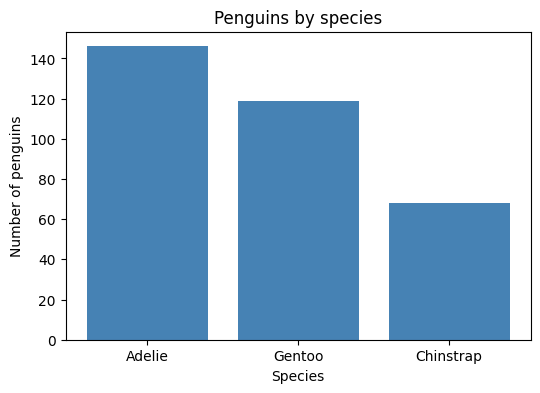

In [11]:
species_counts = penguins_clean['species'].value_counts()
plt.figure(figsize=(6, 4))
plt.bar(species_counts.index, species_counts.values, color='steelblue')
plt.title('Penguins by species')
plt.xlabel('Species')
plt.ylabel('Number of penguins')
plt.show()

a bar chart helps compare the species counts. in the cleaned data, Adelie has the most penguins (146), and Chinstrap has the fewest (68).

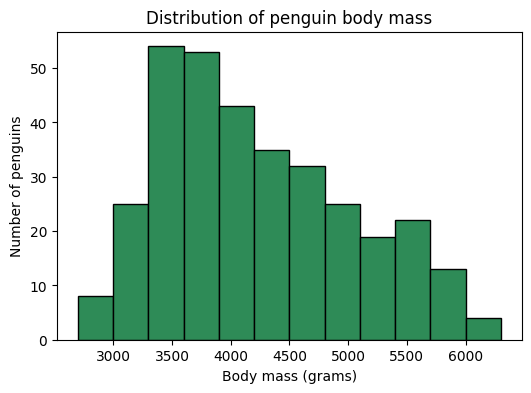

In [12]:
plt.figure(figsize=(6, 4))
plt.hist(penguins_clean['body_mass_g'], bins=12, color='seagreen', edgecolor='black')
plt.title('Distribution of penguin body mass')
plt.xlabel('Body mass (grams)')
plt.ylabel('Number of penguins')
plt.show()

a histogram shows how the body masses are spread out. most are between 3,000 and 5,000 grams, and the full range is 2,700 to 6,300 grams.

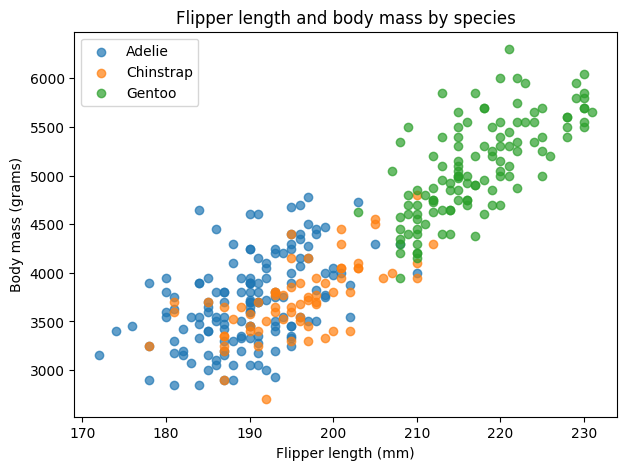

In [13]:
plt.figure(figsize=(7, 5))
adelie = penguins_clean[penguins_clean['species'] == 'Adelie']
chinstrap = penguins_clean[penguins_clean['species'] == 'Chinstrap']
gentoo = penguins_clean[penguins_clean['species'] == 'Gentoo']
plt.scatter(adelie['flipper_length_mm'], adelie['body_mass_g'], label='Adelie', alpha=0.7)
plt.scatter(chinstrap['flipper_length_mm'], chinstrap['body_mass_g'], label='Chinstrap', alpha=0.7)
plt.scatter(gentoo['flipper_length_mm'], gentoo['body_mass_g'], label='Gentoo', alpha=0.7)
plt.title('Flipper length and body mass by species')
plt.xlabel('Flipper length (mm)')
plt.ylabel('Body mass (grams)')
plt.legend()
plt.show()

a scatter plot shows how flipper length and body mass go together. penguins with longer flippers tend to weigh more (r = 0.87 overall), and Gentoo are mostly at the heavier end.

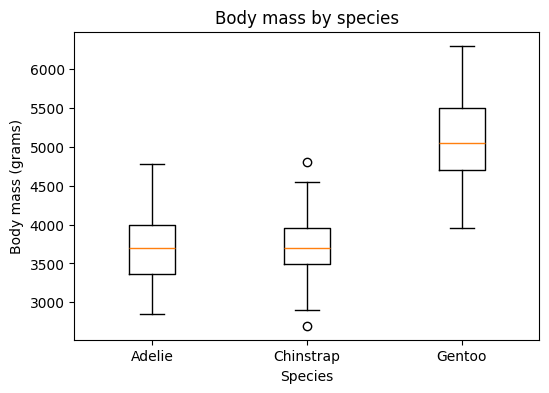

In [14]:
mass_groups = [adelie['body_mass_g'], chinstrap['body_mass_g'], gentoo['body_mass_g']]
plt.figure(figsize=(6, 4))
plt.boxplot(mass_groups)
plt.xticks([1, 2, 3], ['Adelie', 'Chinstrap', 'Gentoo'])
plt.title('Body mass by species')
plt.xlabel('Species')
plt.ylabel('Body mass (grams)')
plt.show()

a box plot compares the middle and spread of body mass for each species. the Gentoo median is higher (5,050 grams) than Adelie and Chinstrap (3,700 grams each), and two Chinstrap points sit outside the whiskers.

what I found: i used 333 complete rows out of 344. in this sample, Adelie is the most common species. on average, Gentoo are heavier and have longer flippers than the other species. flipper length and body mass tend to rise together, but the plot does not show that one causes the other. in this data, Chinstrap are only on Dream and Gentoo are only on Biscoe, so island comparisons also depend on which species were observed there.